# 06 - Baseline prediction and policy scenarios

The frozen MNL predicts six probabilities for each of the 5,000 synthetic people. Every scenario
changes travel attributes and re-predicts with the same frozen model. These are model-based
counterfactuals: they show what the fitted model implies, not what an intervention would cause.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
from src.prediction import load_frozen, predict_probabilities, summarise
from src import scenario_simulation as SS
model, card = load_frozen()
pop = pd.read_csv(C.Paths().synthetic / "synthetic_population.csv")
P = predict_probabilities(model, pop)
table, sus = summarise(P)
display(table.round(2)); print(sus)

,mode,expected_share_pct,expected_count,hard_share_pct,hard_count
0,Walk,7.98,398.82,3.14,157.0
1,Two-wheeler,25.18,1259.15,26.76,1338.0
2,Auto-rickshaw,6.05,302.66,1.98,99.0
3,Car,24.85,1242.55,36.30,1815.0
4,Bus,12.69,634.31,16.80,840.0
5,Suburban rail,23.25,1162.51,15.02,751.0


{'expected_sustainable_share_pct': 43.91275500944541, 'hard_sustainable_share_pct': 34.96}


In [2]:
pd.read_csv(RES / "baseline_share_comparison.csv").round(2)

,mode,observed_train_pct,model_on_train_pct,synthetic_expected_pct,synthetic_hard_pct
0,Walk,8.73,8.73,7.98,3.14
1,Two-wheeler,26.65,26.65,25.18,26.76
2,Auto-rickshaw,6.37,6.37,6.05,1.98
3,Car,24.76,24.76,24.85,36.30
4,Bus,10.61,10.61,12.69,16.80
5,Suburban rail,22.88,22.88,23.25,15.02


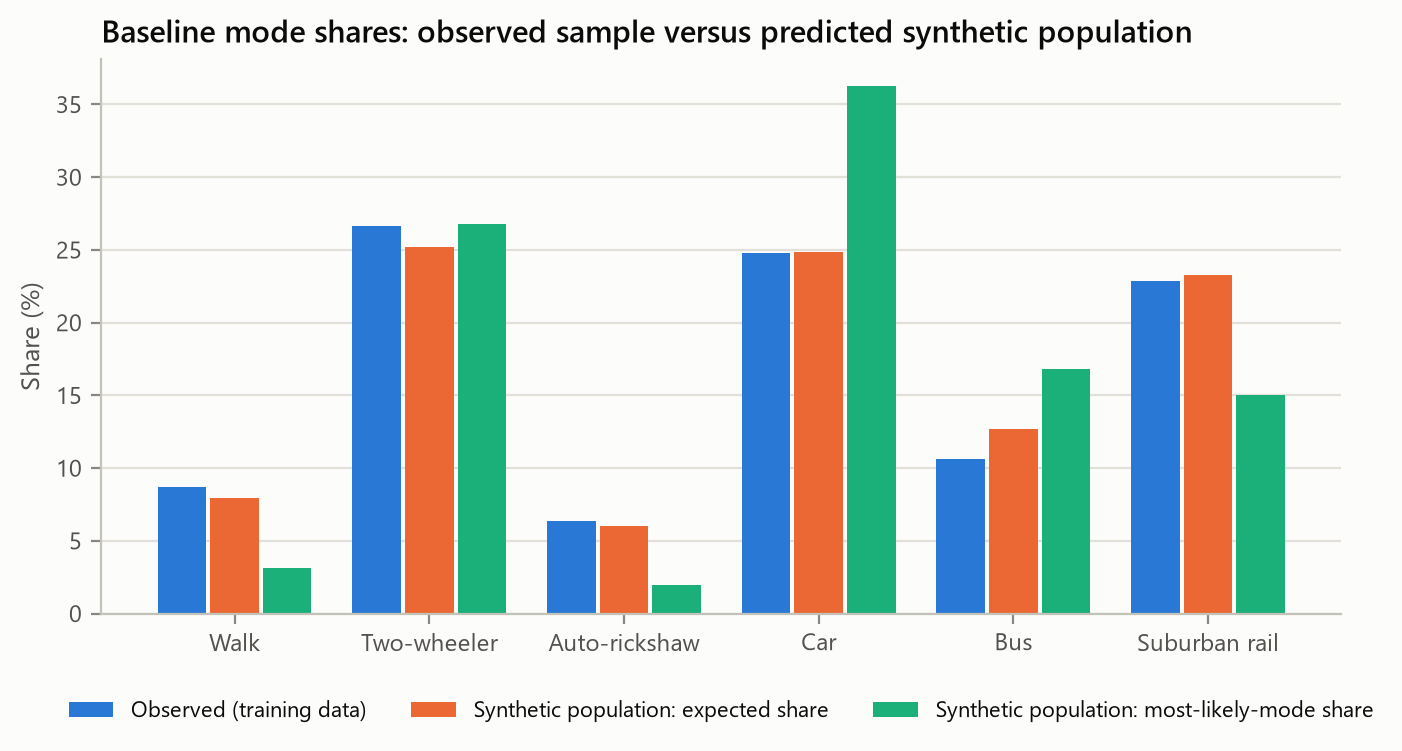

In [3]:
fig("baseline_shares.png", 800)

Expected shares in the synthetic population are close to the observed training shares (bus is 2 points
higher because the synthetic population has slightly more bus availability). The expected sustainable
share is 43.9%. Assigning everybody to their most likely mode gives a very different picture (car
36%, walking 3%, sustainable 35%): hard assignment exaggerates the majority mode in each choice set,
so the expected share is the quantity we optimise.

Availability is respected exactly:

In [4]:
A = pop[[C.AV_COLS[m] for m in C.MODES]].to_numpy()
print("max probability on an unavailable mode:", P.to_numpy()[A == 0].max())
print("rows summing to one:", np.allclose(P.sum(axis=1), 1))

max probability on an unavailable mode: 0.0
rows summing to one: True


## Experiment 1: travel cost

In [5]:
t = SS.experiment_cost(model, pop)
t[["scenario", "expected_sustainable_share_pct", "sustainable_change_pp", "car_pct", "bus_pct", "train_pct"]].round(2)

,scenario,expected_sustainable_share_pct,sustainable_change_pp,car_pct,bus_pct,train_pct
0,Baseline,43.91,0.00,24.85,12.69,23.25
1,Bus fare -5%,43.97,0.05,24.83,12.81,23.20
2,Bus fare -10%,44.02,0.11,24.81,12.93,23.15
3,Bus fare -15%,44.07,0.16,24.79,13.05,23.10
4,Bus fare -20%,44.13,0.21,24.77,13.17,23.05
5,Bus fare -30%,44.23,0.32,24.73,13.40,22.96
6,Bus fare -50%,44.44,0.53,24.66,13.85,22.78
7,Rail fare -5%,44.04,0.13,24.82,12.67,23.40
8,Rail fare -10%,44.17,0.25,24.79,12.65,23.55
9,Rail fare -15%,44.29,0.38,24.75,12.64,23.70


A 50% higher car cost adds 2.3 points of sustainable share, a 50% lower rail fare 1.3 points and a 50%
lower bus fare 0.5 points. Bus measures are weak at population level because only about one person
in five has a bus option at all. Part of the car users who leave move to two-wheelers, which are not
sustainable under our definition.

## Experiment 2: travel time

In [6]:
t = SS.experiment_time(model, pop)
t[["scenario", "expected_sustainable_share_pct", "sustainable_change_pp", "car_pct", "bus_pct", "train_pct"]].round(2)

,scenario,expected_sustainable_share_pct,sustainable_change_pp,car_pct,bus_pct,train_pct
0,Baseline,43.91,0.00,24.85,12.69,23.25
1,Bus time -5%,43.95,0.03,24.84,12.78,23.19
2,Bus time -10%,43.98,0.07,24.83,12.88,23.13
3,Bus time -15%,44.01,0.10,24.82,12.98,23.07
4,Bus time -20%,44.04,0.13,24.81,13.07,23.01
5,Bus time -30%,44.10,0.19,24.80,13.25,22.90
6,Rail time -5%,44.11,0.20,24.81,12.66,23.48
7,Rail time -10%,44.31,0.40,24.76,12.62,23.72
8,Rail time -15%,44.51,0.60,24.72,12.59,23.95
9,Rail time -20%,44.71,0.79,24.67,12.56,24.18


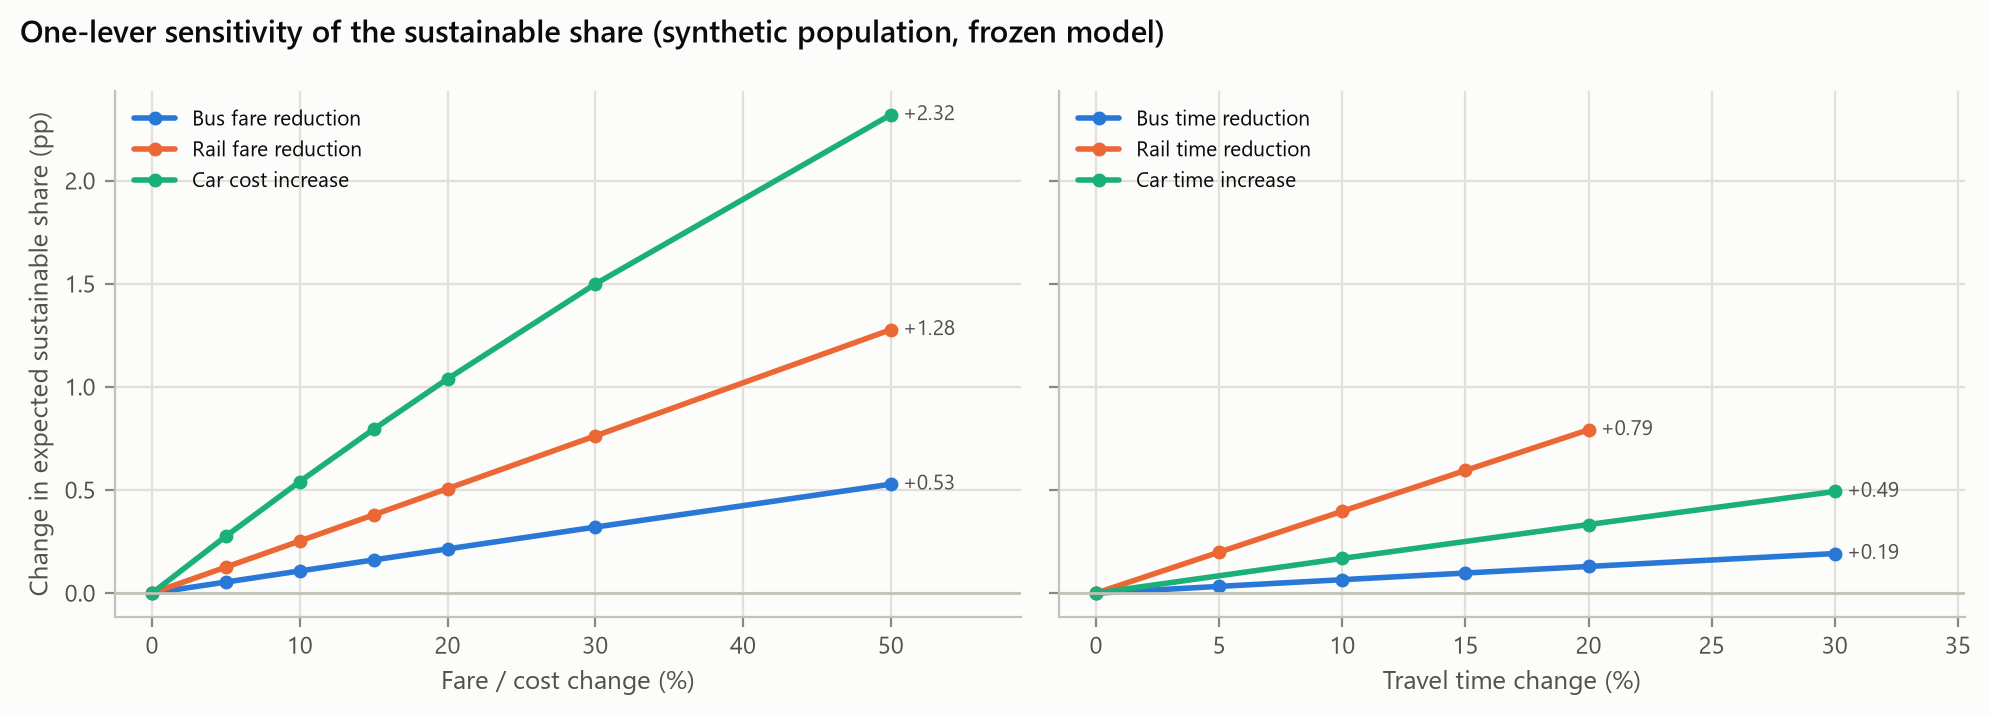

In [7]:
fig("scenario_sensitivity.png", 950)

Time effects are small (a 20% faster rail adds 0.8 points, a 30% faster bus 0.2 points) and, unlike
the cost effects, they depend on the assumed walk-time weight (see notebook 07).

## Experiment 3: availability (extrapolation)

,scenario,expected_sustainable_share_pct,sustainable_change_pp,bus_pct,walk_pct
0,Baseline,43.91,0.00,12.69,7.98
1,Bus offered to 10% of those without it,46.69,2.77,17.48,7.55
2,Bus offered to 25% of those without it,51.07,7.15,24.52,6.97
3,Bus offered to 50% of those without it,58.52,14.61,36.55,5.90
4,Bus offered to 100% of those without it,73.01,29.10,60.36,3.89
5,Walking available for all trips up to 2 km,44.20,0.28,12.68,8.36
6,Walking available for all trips up to 3 km,45.42,1.51,12.67,10.21


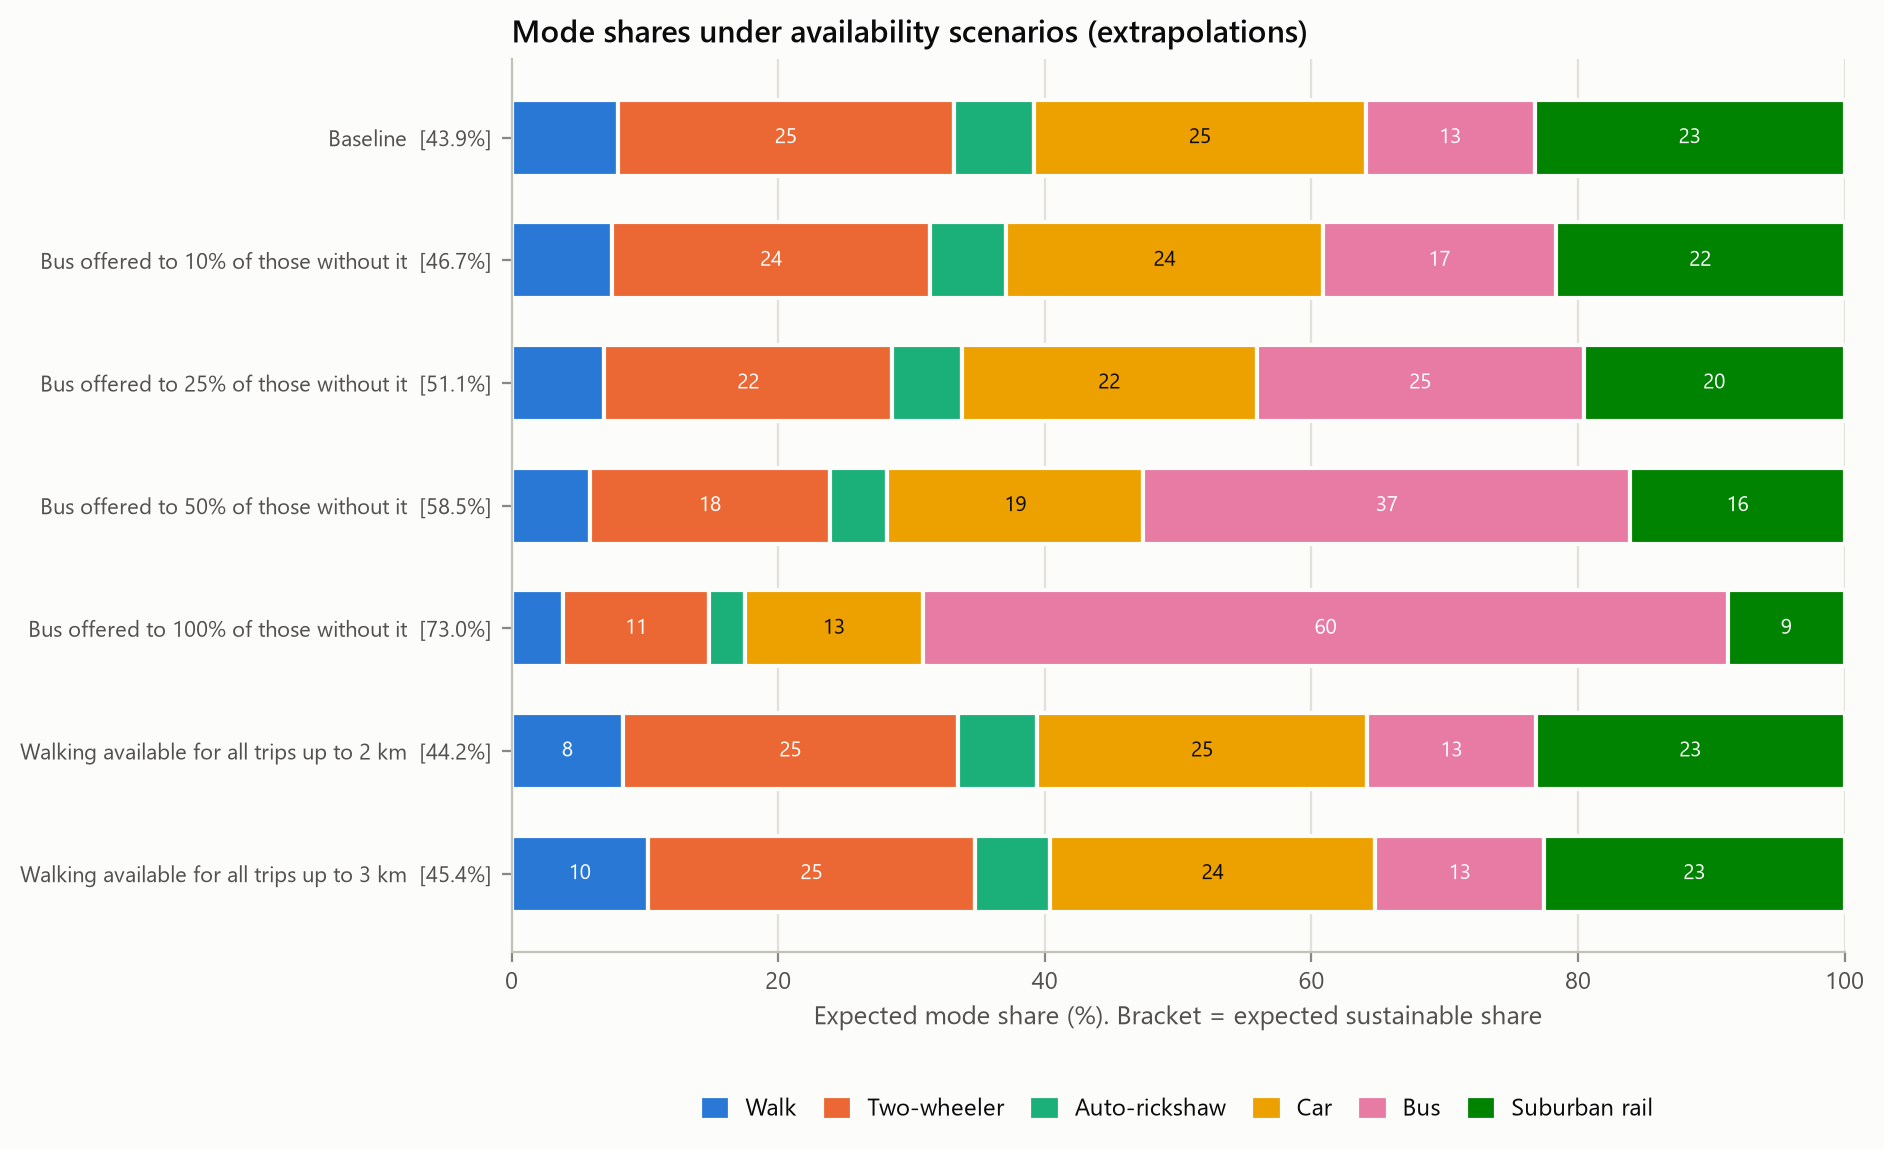

In [8]:
t = SS.experiment_availability(model, pop)
display(t[["scenario", "expected_sustainable_share_pct", "sustainable_change_pp", "bus_pct", "walk_pct"]].round(2))
fig("scenario_availability.png", 850)

Offering a bus to people who currently have none produces very large changes (up to +29 points). These
numbers should not be taken at face value: they put people into choice sets the survey never
observed for them, assume they value the bus exactly like current bus users (who choose it 59% of the
time and may have been recorded as having a bus option *because* they use it) and ignore service
quality. Rail availability cannot be varied at all, since rail is already available to everyone.

## Experiment 4: combined packages

,scenario,expected_sustainable_share_pct,hard_sustainable_share_pct,sustainable_change_pp
0,Baseline,43.91,34.96,0.00
1,"Bus package: time -15%, fare -20%",44.22,35.04,0.31
2,"Rail package: time -10%, fare -20%",44.82,36.70,0.90
3,PT package: bus and rail packages together,45.12,36.78,1.21
4,Push and pull: PT package + car cost +25%,46.40,37.56,2.48
5,All levers at their upper bounds,48.99,41.30,5.07


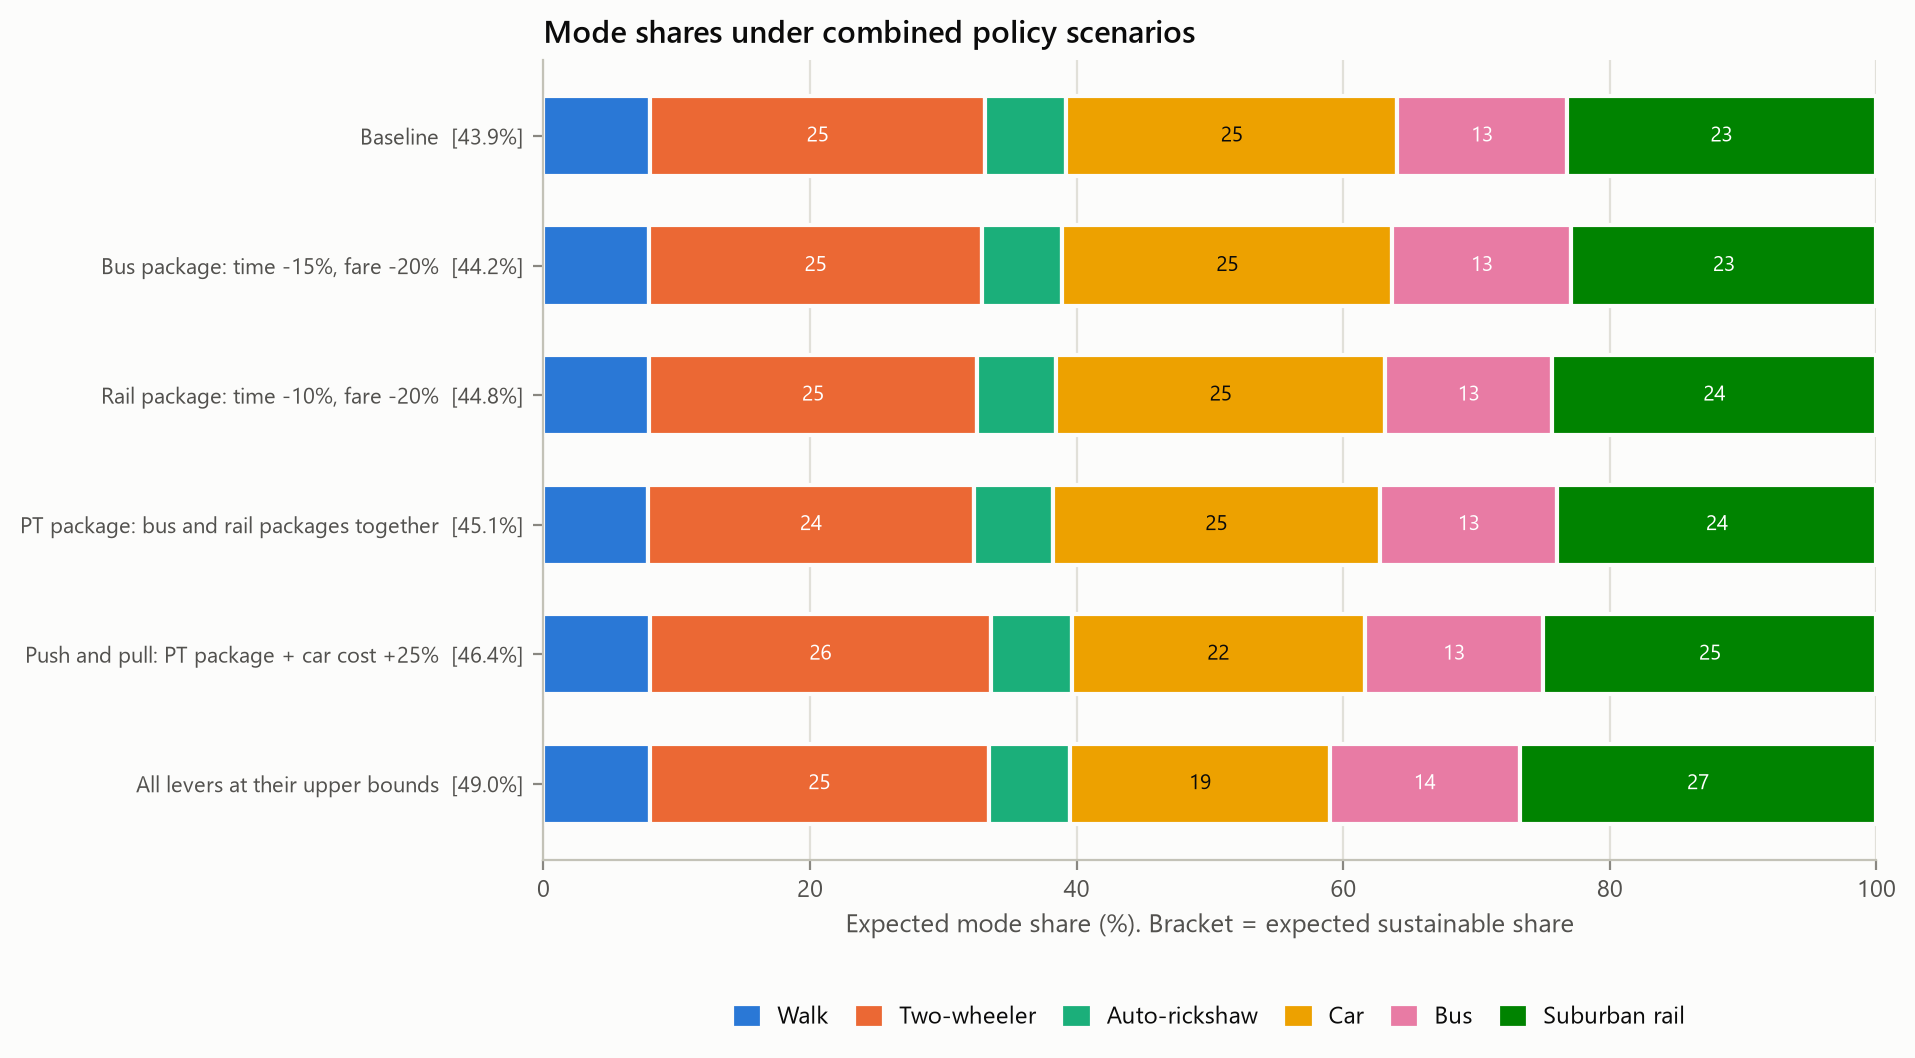

In [9]:
t = SS.experiment_combined(model, pop)
display(t[["scenario", "expected_sustainable_share_pct", "hard_sustainable_share_pct", "sustainable_change_pp"]].round(2))
fig("scenario_combined.png", 900)

## No-change check

In [10]:
same, _, _ = SS.simulate(model, pop, **SS.levers_to_policy({k: 0 for k in C.POLICY_BOUNDS}))
print("max |difference| from baseline:", np.abs(same.to_numpy() - P.to_numpy()).max())

max |difference| from baseline: 0.0
